# Final Pipeline: RetinaNet (Kaggle)

**Мета:** train на всіх, оцінювання на окремому `val/` та створення коректного `submission.csv` test frames.

**Підстава вибору:** у попередньому 3-fold CV RetinaNet + AdamW LR=5e-5 отримала mean fold mAP **0.1550** (baseline 0.1224), з покращенням на всіх folds. Тобто це найкращий оптимальний вибраний нами варіант.

**Вибрані конфігурації:** `train_stride=3`, `epochs=10`, `batch_size=2`, `lr=5e-5`, горизонтальний flip; без змін Focal Loss. `CosineAnnealingLR` у цьому запуску **додаткова зміна** відносно попереднього tuning із constant LR;



## 1. Конфігурація

In [ ]:
from pathlib import Path
import os, sys, subprocess, importlib.util, json, csv, re, random, math, time, io, contextlib, hashlib
from collections import defaultdict
from dataclasses import dataclass, asdict

if importlib.util.find_spec('pycocotools') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'pycocotools'])

SEED = 42
TRAIN_FRAME_STEP = 3 
VAL_FRAME_STEP = 3
EPOCHS = 10
BATCH_SIZE = 2
NUM_WORKERS = 2
LR = 5e-5
WEIGHT_DECAY = 0.01
SCHEDULER = 'cosine'
COSINE_MIN_LR = 1e-5
IMAGE_MIN_SIZE, IMAGE_MAX_SIZE = 800, 1333
USE_AMP = True
VAL_EVERY = 2
MODEL_SCORE_THRESHOLD = 0.02
EVAL_SCORE_THRESHOLD = 0.02
SUBMISSION_SCORE_THRESHOLD = 0.03
MAX_DETECTIONS = 500
USE_TTA_CANDIDATE = True
TTA_NMS_IOU = 0.55
RUN_TRAIN = True
RUN_TEST = True
RUN_SMOKE_TEST = True

DATA_ROOT_OVERRIDE = None
PREP_ROOT_OVERRIDE = None
RESUME_CHECKPOINT = None
RESUME_BEST_CHECKPOINT = None
COCO_WEIGHTS_PATH = None
RUN_NAME = f'retinanet_full_s{TRAIN_FRAME_STEP}_e{EPOCHS}_{SCHEDULER}_lr5e-5'
OUT = Path('/kaggle/working') / RUN_NAME
OUT.mkdir(parents=True, exist_ok=True)

import numpy as np, pandas as pd, torch, torchvision
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm
from torchvision.ops import box_iou, batched_nms
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

assert torch.cuda.is_available(), 'Enable GPU in Kaggle settings before training.'
DEVICE = torch.device('cuda')
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = False
print('GPU:', torch.cuda.get_device_name(0))
print('Torch:', torch.__version__, '| torchvision:', torchvision.__version__)
print('Output:', OUT)

GPU: Tesla T4
Torch: 2.11.0+cu130 | torchvision: 0.26.0+cu130
Output: /kaggle/working/retinanet_full_s3_e10_cosine_lr5e-5


## 2. Налаштування та знаходження competition data + правильні labels


In [ ]:
COMPETITION_SLUG='multiple-object-video-detection-hw-2-ucu-ai-2026'
INPUT_ROOT=Path('/kaggle/input')


def discover_data_root():
    if DATA_ROOT_OVERRIDE:
        p=Path(DATA_ROOT_OVERRIDE)
        assert (p/'train/annotations_coco.json').is_file(), p
        return p
    candidates=[INPUT_ROOT/'competitions'/COMPETITION_SLUG,INPUT_ROOT/COMPETITION_SLUG]
    for p in candidates:
        if (p/'train/annotations_coco.json').is_file() and (p/'test_images.csv').is_file():
            return p
    matches=[f.parent.parent for f in INPUT_ROOT.rglob('annotations_coco.json')
             if f.parent.name=='train' and (f.parent.parent/'test_images.csv').is_file()]
    if len(matches)!=1:
        raise FileNotFoundError(f'Expected 1 competition root, found {matches}. Set DATA_ROOT_OVERRIDE.')
    return matches[0]


def discover_prep_root():
    if PREP_ROOT_OVERRIDE:
        p=Path(PREP_ROOT_OVERRIDE)
        assert (p/'train.json').is_file() and (p/'val.json').is_file(), p
        return p
    matches=[f.parent for f in INPUT_ROOT.rglob('train.json') if (f.parent/'val.json').is_file()]
    if not matches: return None
    if len(matches)>1:
        print('Multiple preprocessed versions found; reading raw COCO for deterministic behavior:',matches)
        return None
    return matches[0]

DATA_ROOT=discover_data_root()
PREP_ROOT=discover_prep_root()
print('DATA_ROOT=',DATA_ROOT)
print('PREP_ROOT=',PREP_ROOT,'(None = read original COCO)')
print('sample_submission:', (DATA_ROOT/'sample_submission.csv').exists())

CLASS_NAMES={1:'person', 2:'bicycle', 3:'car', 4:'van', 5:'truck', 6:'tricycle', 7:'bus', 8:'motor'}
NUM_CLASSES=9


def canonical_rel(split, raw_name):
    rel=str(raw_name).replace('\\','/').lstrip('/')
    if rel.startswith(f'{split}/'): rel=rel[len(split)+1:]
    if (DATA_ROOT/split/rel).is_file(): return rel
    if (DATA_ROOT/split/'images'/rel).is_file(): return 'images/'+rel
    raise FileNotFoundError(f'Cannot locate image in split {split}: {raw_name}')


def read_coco_split(split):
    doc=json.loads((DATA_ROOT/split/'annotations_coco.json').read_text())
    anns_by_img=defaultdict(list)
    for a in doc['annotations']: anns_by_img[a['image_id']].append(a)
    records=[]
    for im in doc['images']:
        w,h=int(im['width']),int(im['height'])
        boxes,labels,ignored=[],[],[]
        for a in anns_by_img[im['id']]:
            x,y,bw,bh=map(float,a['bbox'])
            x1,y1=max(0.,x),max(0.,y)
            x2,y2=min(float(w),x+bw),min(float(h),y+bh)
            if x2<=x1 or y2<=y1: continue
            box=[x1,y1,x2,y2]
            cls=int(a.get('category_id',-1))
            if int(a.get('iscrowd',0))==1 or cls not in CLASS_NAMES:
                ignored.append(box)
            else:
                boxes.append(box);labels.append(cls)
        records.append(dict(image_id=im['id'],file_name=canonical_rel(split, im['file_name']),
                            boxes=boxes,labels=labels,ignored_boxes=ignored))
    return records


def load_preprocessed_split(split):
    records=json.loads((PREP_ROOT/f'{split}.json').read_text())
    for r in records:
        r['file_name']=canonical_rel(split,r['file_name'])
    return records

train_records=load_preprocessed_split('train') if PREP_ROOT else read_coco_split('train')
val_records=load_preprocessed_split('val') if PREP_ROOT else read_coco_split('val')
assert len(train_records)==24201, f'Unexpected train count: {len(train_records)}'
assert len(val_records)==2846, f'Unexpected official val count: {len(val_records)}'
for part in (train_records,val_records):
    for r in part:
        assert len(r['boxes'])==len(r['labels'])
        assert all(int(label) in CLASS_NAMES for label in r['labels'])
print('Train:',len(train_records),'| Official val:',len(val_records))

DATA_ROOT= /kaggle/input/datasets/nastyadovbenchuk/multiple-object-video-detection
PREP_ROOT= /kaggle/input/datasets/nastyadovbenchuk/preprocessing (None = read original COCO)
sample_submission: False
Train: 24201 | Official val: 2846


## 3. Відбір кадрів + DataLoader

Беремо кожен `TRAIN_FRAME_STEP`-й кадр всередині кожного кліпу. 

`ignored_boxes` - обробляються окремо у RetinaNet loss.

In [3]:
def sequence_name(rec):
    return Path(str(rec['file_name']).replace('\\','/')).parent.name


def frame_sort_key(rec):
    stem=Path(rec['file_name']).stem
    m=re.search(r'(\d+)$',stem)
    return (int(m.group(1)) if m else -1,stem)


def subsample_by_sequence(records,stride):
    assert stride>=1
    groups=defaultdict(list)
    for r in records: groups[sequence_name(r)].append(r)
    return [r for seq in sorted(groups)
            for r in sorted(groups[seq],key=frame_sort_key)[::stride]]

selected_train=subsample_by_sequence(train_records,TRAIN_FRAME_STEP)
selected_val=subsample_by_sequence(val_records,VAL_FRAME_STEP)
assert {sequence_name(r) for r in train_records}.isdisjoint({sequence_name(r) for r in val_records}), 'Train/val video leakage!'
assert len(set(r['file_name'] for r in selected_train))==len(selected_train)
print(f'Train (stride {TRAIN_FRAME_STEP}): {len(selected_train)} / {len(train_records)}')
print(f'Val (stride {VAL_FRAME_STEP}): {len(selected_val)} / {len(val_records)}')
print('Train clips:',len({sequence_name(r) for r in selected_train}),
      '| Val clips:',len({sequence_name(r) for r in selected_val}))

class DetectionDataset(Dataset):
    def __init__(self,records,split,augment=False):
        self.records=list(records);self.split=split;self.augment=augment
    def __len__(self):return len(self.records)
    def __getitem__(self,index):
        r=self.records[index]
        with Image.open(DATA_ROOT/self.split/r['file_name']) as im:
            rgb=np.asarray(im.convert('RGB')).copy()
        h,w=rgb.shape[:2]
        image=torch.from_numpy(rgb).permute(2,0,1).contiguous().float()/255.
        boxes=torch.as_tensor(r['boxes'],dtype=torch.float32).reshape(-1,4).clone()
        labels=torch.as_tensor(r['labels'],dtype=torch.int64)
        ignores=torch.as_tensor(r.get('ignored_boxes',[]),dtype=torch.float32).reshape(-1,4).clone()
        if self.augment and random.random()<0.5:
            image=image.flip(-1)
            for b in (boxes,ignores):
                if len(b):
                    left=b[:,0].clone();right=b[:,2].clone()
                    b[:,0]=w-right;b[:,2]=w-left
        target={'boxes':boxes,'labels':labels,'ignored_boxes':ignores,
                'image_id':torch.as_tensor(int(r['image_id']))}
        return image,target


def collate_fn(batch):
    images,targets=zip(*batch)
    return list(images),list(targets)


def seed_worker(worker_id):
    seed=torch.initial_seed()%2**32
    random.seed(seed);np.random.seed(seed)

train_ds=DetectionDataset(selected_train,'train',augment=True)
val_ds=DetectionDataset(selected_val,'val',augment=False)
train_loader=DataLoader(train_ds,batch_size=BATCH_SIZE,shuffle=True,
                        num_workers=NUM_WORKERS,collate_fn=collate_fn,pin_memory=True,
                        worker_init_fn=seed_worker,persistent_workers=NUM_WORKERS>0)
val_loader=DataLoader(val_ds,batch_size=1,shuffle=False,
                      num_workers=NUM_WORKERS,collate_fn=collate_fn,pin_memory=True,
                      persistent_workers=NUM_WORKERS>0)
print('Train batches per epoch:',len(train_loader))

Train (stride 3): 8090 / 24201
Val (stride 3): 951 / 2846
Train clips: 56 | Val clips: 7
Train batches per epoch: 4045


## 4. RetinaNet ResNet50-FPN
Беремо COCO pretrained RetinaNet:
- замінюємо classification head на 9 класів;
- ігноруємо anchors, центр яких лежить в ignored region, лише якщо вони не збігаються з позитивною GT; 
- `ignored_boxes` окремо масштабуємо всередині `model.transform.resize`.

In [ ]:
from types import MethodType
from torchvision.models.detection import retinanet_resnet50_fpn, RetinaNet_ResNet50_FPN_Weights
from torchvision.models.detection.retinanet import RetinaNetClassificationHead
from torchvision.models.detection.transform import resize_boxes
from torchvision.models.detection import _utils as det_utils


def make_model():
    if COCO_WEIGHTS_PATH:
        model=retinanet_resnet50_fpn(weights=None,weights_backbone=None,
                                     min_size=IMAGE_MIN_SIZE,max_size=IMAGE_MAX_SIZE,
                                     score_thresh=MODEL_SCORE_THRESHOLD,
                                     detections_per_img=MAX_DETECTIONS)
        weights=torch.load(COCO_WEIGHTS_PATH,map_location='cpu',weights_only=True)
        model.load_state_dict(weights.get('state_dict',weights),strict=True)
    elif RESUME_CHECKPOINT or RESUME_BEST_CHECKPOINT or (OUT/'last.pt').exists() or (OUT/'best_model.pt').exists():
        model=retinanet_resnet50_fpn(weights=None,weights_backbone=None,
                                     min_size=IMAGE_MIN_SIZE,max_size=IMAGE_MAX_SIZE,
                                     score_thresh=MODEL_SCORE_THRESHOLD,
                                     detections_per_img=MAX_DETECTIONS)
    else:
        model=retinanet_resnet50_fpn(weights=RetinaNet_ResNet50_FPN_Weights.DEFAULT,
                                     min_size=IMAGE_MIN_SIZE,max_size=IMAGE_MAX_SIZE,
                                     score_thresh=MODEL_SCORE_THRESHOLD,
                                     detections_per_img=MAX_DETECTIONS)
    anchors=model.anchor_generator.num_anchors_per_location()[0]
    model.head.classification_head=RetinaNetClassificationHead(
        model.backbone.out_channels,anchors,NUM_CLASSES)

    original_resize=model.transform.resize
    def resize_with_ignore(image,target=None):
        old_size=image.shape[-2:]
        image,target=original_resize(image,target)
        if target is not None and 'ignored_boxes' in target:
            target['ignored_boxes']=resize_boxes(target['ignored_boxes'],old_size,image.shape[-2:])
        return image,target
    model.transform.resize=resize_with_ignore

    def compute_loss_with_ignore(self,targets,head_outputs,anchors):
        matched_idxs=[]
        for anchor,target in zip(anchors,targets):
            boxes=target['boxes']
            if len(boxes):
                matches=self.proposal_matcher(box_iou(boxes,anchor))
            else:
                matches=torch.full((len(anchor),),-1,dtype=torch.long,device=anchor.device)
            ignore=target.get('ignored_boxes')
            if ignore is not None and len(ignore):
                centers=(anchor[:,:2]+anchor[:,2:])/2
                mask=torch.zeros(len(anchor),dtype=torch.bool,device=anchor.device)
                for region in ignore.unique(dim=0):
                    mask |= ((centers[:,0]>=region[0]) & (centers[:,0]<=region[2]) &
                             (centers[:,1]>=region[1]) & (centers[:,1]<=region[3]))
                matches[(matches<0)&mask]=det_utils.Matcher.BETWEEN_THRESHOLDS
            matched_idxs.append(matches)
        return self.head.compute_loss(targets,head_outputs,anchors,matched_idxs)
    model.compute_loss=MethodType(compute_loss_with_ignore,model)
    return model.to(DEVICE)

model=make_model()
print('Model created:',model.__class__.__name__)

Downloading: "https://download.pytorch.org/models/retinanet_resnet50_fpn_coco-eeacb38b.pth" to /root/.cache/torch/hub/checkpoints/retinanet_resnet50_fpn_coco-eeacb38b.pth


100%|██████████| 130M/130M [00:00<00:00, 184MB/s] 


Model created: RetinaNet


## 5. Перевірка одного batch 

In [5]:
def send_batch(images,targets):
    return ([img.to(DEVICE,non_blocking=True) for img in images],
            [{k:v.to(DEVICE,non_blocking=True) for k,v in t.items()} for t in targets])

if RUN_SMOKE_TEST:
    images,targets=next(iter(train_loader))
    images,targets=send_batch(images,targets)
    model.train()
    with torch.no_grad(),torch.autocast('cuda',enabled=USE_AMP):
        losses=model(images,targets)
    print('Smoke train losses:',{k:round(v.item(),4) for k,v in losses.items()})
    assert all(torch.isfinite(v) for v in losses.values())
    model.eval()
    with torch.inference_mode(),torch.autocast('cuda',enabled=USE_AMP):
        pred=model(images[:1])[0]
    print('Smoke inference:',len(pred['scores']),'detections')
    del images,targets,losses,pred
    torch.cuda.empty_cache()

Smoke train losses: {'classification': 1.1302, 'bbox_regression': 0.3429}
Smoke inference: 0 detections


## 6. Official validation: COCO mAP, AP50, AP_small

Ігноровані регіони оцінюються COCO-style через crowd annotations для кожного цільового класу. Для оцінювання вибрано `maxDets=[1,10,100]`.

In [ ]:
def xyxy_to_xywh(box):
    x1,y1,x2,y2=[float(v) for v in box]
    return [x1,y1,max(0.,x2-x1),max(0.,y2-y1)]


def build_coco_gt(records):
    images=[];annotations=[];ann_id=1
    for r in records:
        imid=int(r['image_id'])
        images.append(dict(id=imid,file_name=r['file_name']))
        for box,label in zip(r['boxes'],r['labels']):
            xywh=xyxy_to_xywh(box)
            if xywh[2]<=0 or xywh[3]<=0:continue
            annotations.append(dict(id=ann_id,image_id=imid,category_id=int(label),
                                    bbox=xywh,area=xywh[2]*xywh[3],iscrowd=0))
            ann_id+=1
        for box in r.get('ignored_boxes',[]):
            xywh=xyxy_to_xywh(box)
            if xywh[2]<=0 or xywh[3]<=0:continue
            for label in CLASS_NAMES:
                annotations.append(dict(id=ann_id,image_id=imid,category_id=label,
                                        bbox=xywh,area=xywh[2]*xywh[3],iscrowd=1))
                ann_id+=1
    coco=COCO();coco.dataset=dict(images=images,annotations=annotations,
        categories=[dict(id=k,name=v) for k,v in CLASS_NAMES.items()],info={},licenses=[])
    with contextlib.redirect_stdout(io.StringIO()):coco.createIndex()
    return coco

with contextlib.redirect_stdout(io.StringIO()):
    COCO_VAL_GT=build_coco_gt(selected_val)


def coco_evaluate(predictions):
    with contextlib.redirect_stdout(io.StringIO()):
        if predictions:
            dt=COCO_VAL_GT.loadRes(predictions)
        else:
            dt=COCO();dt.dataset=dict(images=COCO_VAL_GT.dataset['images'],
                annotations=[],categories=COCO_VAL_GT.dataset['categories'],info={},licenses=[])
            dt.createIndex()
        ev=COCOeval(COCO_VAL_GT,dt,'bbox')
        ev.params.imgIds=[int(r['image_id']) for r in selected_val]
        ev.params.catIds=list(CLASS_NAMES)
        ev.params.maxDets=[1,10,100]
        ev.evaluate();ev.accumulate();ev.summarize()
    stats=[float(x) for x in ev.stats]
    return {'mAP':stats[0],'AP50':stats[1],'AP75':stats[2],
            'AP_small':stats[3],'AP_medium':stats[4],'AP_large':stats[5]}


def clean_predictions(output,width,height,threshold):
    boxes=output['boxes'].float().detach().cpu().clone().reshape(-1,4)
    labels=output['labels'].long().detach().cpu().clone().reshape(-1)
    scores=output['scores'].float().detach().cpu().clone().reshape(-1)
    boxes[:,[0,2]]=boxes[:,[0,2]].clamp(0,width)
    boxes[:,[1,3]]=boxes[:,[1,3]].clamp(0,height)
    keep=((scores>=threshold)&torch.isfinite(scores)&torch.isfinite(boxes).all(dim=1)&
          (boxes[:,2]>boxes[:,0])&(boxes[:,3]>boxes[:,1])&
          (labels>=1)&(labels<=8))
    return {'boxes':boxes[keep],'labels':labels[keep],'scores':scores[keep]}


def predict_batch(model,images):
    model.eval()
    x=[im.to(DEVICE,non_blocking=True) for im in images]
    with torch.inference_mode(),torch.autocast('cuda',enabled=USE_AMP):
        results=model(x)
    return results


def predict_image(model,image,tta=False,score_threshold=EVAL_SCORE_THRESHOLD):
    # Batched input support in non-TTA path is retained for test
    orig=predict_batch(model,[image])[0]
    h,w=image.shape[-2:]
    base=clean_predictions(orig,w,h,score_threshold)
    if not tta:return base
    flipped=predict_batch(model,[image.flip(-1)])[0]
    flipped=clean_predictions(flipped,w,h,score_threshold)
    if len(flipped['boxes']):
        b=flipped['boxes'];x1=b[:,0].clone();x2=b[:,2].clone()
        b[:,0]=w-x2;b[:,2]=w-x1
    boxes=torch.cat([base['boxes'],flipped['boxes']])
    scores=torch.cat([base['scores'],flipped['scores']])
    labels=torch.cat([base['labels'],flipped['labels']])
    if len(boxes):
        order=batched_nms(boxes,scores,labels,TTA_NMS_IOU)[:MAX_DETECTIONS]
        boxes,scores,labels=boxes[order],scores[order],labels[order]
    return {'boxes':boxes,'scores':scores,'labels':labels}


def predict_official_val(model,tta=False):
    preds=[];durations=[]
    for images,targets in tqdm(val_loader,desc='Val TTA' if tta else 'Val baseline',leave=False):
        torch.cuda.synchronize();start=time.perf_counter()
        output=predict_image(model,images[0],tta=tta,score_threshold=EVAL_SCORE_THRESHOLD)
        torch.cuda.synchronize();durations.append(time.perf_counter()-start)
        imid=int(targets[0]['image_id'])
        for box,label,score in zip(output['boxes'].tolist(),output['labels'].tolist(),output['scores'].tolist()):
            preds.append(dict(image_id=imid,category_id=int(label),bbox=xyxy_to_xywh(box),score=float(score)))
    metrics=coco_evaluate(preds)
    metrics['inference_ms_per_image']=round(1000*float(np.mean(durations)),2)
    metrics['images_evaluated']=len(selected_val)
    metrics['n_predictions']=len(preds)
    return metrics,preds

## 7. Train loop: AMP, checkpoints, resume, best on official val

`last.pt` містить model, optimizer, scaler, scheduler, epoch і histories. <br>
`best_model.pt` — лише модель з найкращим official-val mAP.

In [7]:
SIGNATURE=dict(model='retinanet_resnet50_fpn',train_stride=TRAIN_FRAME_STEP,
  val_stride=VAL_FRAME_STEP,epochs=EPOCHS,batch_size=BATCH_SIZE,lr=LR,
  weight_decay=WEIGHT_DECAY,scheduler=SCHEDULER,min_size=IMAGE_MIN_SIZE,
  max_size=IMAGE_MAX_SIZE,amp=USE_AMP,seed=SEED)
SIGNATURE_HASH=hashlib.sha256(json.dumps(SIGNATURE,sort_keys=True).encode()).hexdigest()
(OUT/'config.json').write_text(json.dumps(dict(SIGNATURE,signature_hash=SIGNATURE_HASH),indent=2))

optimizer=torch.optim.AdamW(model.parameters(),lr=LR,weight_decay=WEIGHT_DECAY)
if SCHEDULER=='cosine':
    scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=EPOCHS,eta_min=COSINE_MIN_LR)
elif SCHEDULER=='constant':
    scheduler=torch.optim.lr_scheduler.LambdaLR(optimizer,lambda epoch:1.0)
else:
    raise ValueError('SCHEDULER must be cosine or constant')
scaler=torch.amp.GradScaler('cuda',enabled=USE_AMP)
LAST=OUT/'last.pt'
BEST=OUT/'best_model.pt'
if RESUME_BEST_CHECKPOINT and not BEST.exists():
    import shutil
    shutil.copy2(RESUME_BEST_CHECKPOINT,BEST)
start_epoch=0;best_map=-1.;history=[]


def load_last(path):
    global start_epoch,best_map,history
    p=Path(path)
    ckpt=torch.load(p,map_location='cpu',weights_only=True)
    assert ckpt['signature_hash']==SIGNATURE_HASH, f'Config mismatch! {p}'
    model.load_state_dict(ckpt['model'])
    optimizer.load_state_dict(ckpt['optimizer'])
    scheduler.load_state_dict(ckpt['scheduler'])
    scaler.load_state_dict(ckpt['scaler'])
    start_epoch=int(ckpt['epoch'])
    best_map=float(ckpt['best_map'])
    history=ckpt['history']
    print(f'Resumed epoch {start_epoch}/{EPOCHS} | best val mAP={best_map:.4f}')
    del ckpt

if RESUME_CHECKPOINT:
    load_last(RESUME_CHECKPOINT)
elif LAST.exists():
    load_last(LAST)


def atomic_torch_save(payload,path):
    tmp=path.with_name(path.name+'.tmp')
    torch.save(payload,tmp)
    tmp.replace(path)


def train_epoch(epoch):
    model.train();t0=time.perf_counter()
    sums=defaultdict(float);n=0
    for images,targets in tqdm(train_loader,desc=f'Epoch {epoch}/{EPOCHS}',leave=False):
        images,targets=send_batch(images,targets)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast('cuda',enabled=USE_AMP):
            parts=model(images,targets)
            loss=sum(parts.values())
        if not torch.isfinite(loss):
            raise RuntimeError(f'Invalid loss at epoch {epoch}: {parts}')
        scaler.scale(loss).backward()
        scaler.step(optimizer);scaler.update()
        n+=len(images)
        for k,v in parts.items():sums[k]+=v.detach().item()*len(images)
    return dict(loss=sum(sums.values())/max(n,1),
                classification_loss=sums['classification']/max(n,1),
                bbox_loss=sums['bbox_regression']/max(n,1),
                epoch_minutes=(time.perf_counter()-t0)/60)


if RUN_TRAIN:
    for epoch in range(start_epoch+1,EPOCHS+1):
        current_lr=optimizer.param_groups[0]['lr']
        logs=train_epoch(epoch)
        logs.update(epoch=epoch,lr=current_lr)
        if epoch%VAL_EVERY==0 or epoch==EPOCHS:
            metrics,_=predict_official_val(model,tta=False)
            logs.update({'val_'+k:v for k,v in metrics.items()})
            print('Official val:',{k:round(metrics[k],4) for k in ('mAP','AP50','AP_small')})
            if metrics['mAP']>best_map:
                best_map=metrics['mAP']
                atomic_torch_save({'model':model.state_dict(),'epoch':epoch,
                                   'val_metrics':metrics,'signature_hash':SIGNATURE_HASH},BEST)
                print('New BEST:',BEST)
        history.append(logs)
        scheduler.step()
        atomic_torch_save(dict(epoch=epoch,model=model.state_dict(),
            optimizer=optimizer.state_dict(),scheduler=scheduler.state_dict(),
            scaler=scaler.state_dict(),best_map=best_map,history=history,
            signature_hash=SIGNATURE_HASH),LAST)
        pd.DataFrame(history).to_csv(OUT/'train_history.csv',index=False)
        print(f'Epoch {epoch}: train loss {logs["loss"]:.4f} | LR {current_lr:.2e} | {logs["epoch_minutes"]:.1f} min')
    print('Best official-val mAP=',best_map)
else:
    print('Training disabled. Expecting saved best_model.pt or RESUME_CHECKPOINT.')

Epoch 1/10:   0%|          | 0/4045 [00:00<?, ?it/s]

Epoch 1: train loss 0.5364 | LR 5.00e-05 | 32.1 min


Epoch 2/10:   0%|          | 0/4045 [00:00<?, ?it/s]

Val baseline:   0%|          | 0/951 [00:00<?, ?it/s]

Official val: {'mAP': 0.1512, 'AP50': 0.294, 'AP_small': 0.0546}
New BEST: /kaggle/working/retinanet_full_s3_e10_cosine_lr5e-5/best_model.pt
Epoch 2: train loss 0.3889 | LR 4.90e-05 | 31.9 min


Epoch 3/10:   0%|          | 0/4045 [00:00<?, ?it/s]

... (15 outputs left out)

Epoch 9: train loss 0.1951 | LR 1.38e-05 | 31.8 min


Epoch 10/10:   0%|          | 0/4045 [00:00<?, ?it/s]

Val baseline:   0%|          | 0/951 [00:00<?, ?it/s]

Official val: {'mAP': 0.1434, 'AP50': 0.2834, 'AP_small': 0.0545}
Epoch 10: train loss 0.1802 | LR 1.10e-05 | 31.7 min
Best official-val mAP= 0.15276342845335084


## 8. Найкращий checkpoint + inference strategy A/B

Перевіряємо validation кадри зі звичайним inference та horizontal-flip TTA. TTA поєднує результати двох проходів і застосовує class-aware NMS.

In [9]:
if not BEST.exists() and RESUME_CHECKPOINT:
    raise FileNotFoundError('Need best_model.pt too: set RESUME_BEST_CHECKPOINT to restore best weights.')
assert BEST.exists(), 'No best_model.pt: run training (or restore previous best checkpoint to OUT).'
ckpt_best=torch.load(BEST,map_location='cpu',weights_only=True)
assert ckpt_best['signature_hash']==SIGNATURE_HASH
model.load_state_dict(ckpt_best['model'])
model.eval()
print('Loaded BEST epoch:',ckpt_best['epoch'],'| selected official-val mAP:',ckpt_best['val_metrics']['mAP'])
del ckpt_best

baseline_metrics,baseline_preds=predict_official_val(model,tta=False)
results={'without_tta':baseline_metrics}
chosen_tta=False
if USE_TTA_CANDIDATE:
    flip_metrics,flip_preds=predict_official_val(model,tta=True)
    results['flip_tta']=flip_metrics
    chosen_tta=flip_metrics['mAP']>baseline_metrics['mAP']
    (OUT/'val_preds_tta.json').write_text(json.dumps(flip_preds))
(OUT/'val_preds_baseline.json').write_text(json.dumps(baseline_preds))
(OUT/'val_inference_comparison.json').write_text(json.dumps(results,indent=2))
print(pd.DataFrame(results).T[['mAP','AP50','AP_small','inference_ms_per_image']])
print('TTA selected:',chosen_tta)
(OUT/'selected_inference.json').write_text(json.dumps({'tta':chosen_tta,
  'validation_score_threshold':EVAL_SCORE_THRESHOLD,
  'submission_score_threshold':SUBMISSION_SCORE_THRESHOLD,
  'tta_nms_iou':TTA_NMS_IOU},indent=2))

Loaded BEST epoch: 6 | selected official-val mAP: 0.15276342845335084


Val baseline:   0%|          | 0/951 [00:00<?, ?it/s]

Val TTA:   0%|          | 0/951 [00:00<?, ?it/s]

                  mAP      AP50  AP_small  inference_ms_per_image
without_tta  0.152763  0.299411  0.058170                   84.48
flip_tta     0.162377  0.319006  0.070475                  204.60
TTA selected: True


116

Оскіль з використанням ТТА результат покрищився використовуємо його.

## 9. Submission: **image_id,PredictionString**


In [10]:
print("test_images.csv:", (DATA_ROOT / "test_images.csv").exists())

print(
    "Sample submission files:",
    list(Path("/kaggle/input").rglob("sample_submission.csv"))
)

test_images.csv: True
Sample submission files: []


In [ ]:
TEST_IMAGES = DATA_ROOT / 'test_images.csv'
assert TEST_IMAGES.is_file(), f'Missing test metadata: {TEST_IMAGES}'

test_info = pd.read_csv(TEST_IMAGES, dtype={'image_id': str}, keep_default_na=False)
required = {'image_id', 'file_name', 'width', 'height'}
missing = required - set(test_info.columns)
assert not missing, f'Missing columns in test_images.csv: {sorted(missing)}'
assert len(test_info) > 0, 'test_images.csv is empty'
assert test_info['image_id'].notna().all() and test_info['image_id'].ne('').all()
assert test_info['image_id'].is_unique, 'Duplicate image_id in test_images.csv'
assert test_info['file_name'].notna().all() and test_info['file_name'].ne('').all()
assert (pd.to_numeric(test_info['width']) > 0).all()
assert (pd.to_numeric(test_info['height']) > 0).all()
print('Test frames:', len(test_info), '| Example:', test_info.iloc[0].to_dict())


def resolve_test_image_path(file_name):
    rel = Path(str(file_name).replace('\\', '/').lstrip('/'))
    candidates = [DATA_ROOT / rel, DATA_ROOT / 'test' / rel,
                  DATA_ROOT / 'test' / 'images' / rel]
    for path in candidates:
        if path.is_file():
            return path
    raise FileNotFoundError(
        f'Test image not found: {file_name!r}; tried: {candidates}'
    )


class TestFrames(Dataset):
    def __init__(self, rows):
        self.rows = rows.to_dict('records')
    def __len__(self):
        return len(self.rows)
    def __getitem__(self, index):
        row = self.rows[index]
        path = resolve_test_image_path(row['file_name'])
        with Image.open(path) as im:
            arr = np.asarray(im.convert('RGB')).copy()
        h, w = arr.shape[:2]
        assert (w, h) == (int(row['width']), int(row['height'])), (path, w, h)
        return (torch.from_numpy(arr).permute(2, 0, 1).float() / 255.,
                str(row['image_id']), w, h)


def collate_test(batch):
    return list(batch)


def to_prediction_string(output, score_threshold):
    rows = []
    for box, label, score in zip(output['boxes'].tolist(),
                                 output['labels'].tolist(),
                                 output['scores'].tolist()):
        if score < score_threshold:
            continue
        x, y, w, h = xyxy_to_xywh(box)
        if w <= 0 or h <= 0:
            continue
        rows.append(f'{int(label)-1} {score:.6f} {x:.2f} {y:.2f} {w:.2f} {h:.2f}')
    return ' '.join(rows[:MAX_DETECTIONS])


if RUN_TEST:
    test_loader = DataLoader(
        TestFrames(test_info), batch_size=BATCH_SIZE, shuffle=False,
        num_workers=NUM_WORKERS, collate_fn=collate_test, pin_memory=True
    )
    strings = {}
    for batch in tqdm(test_loader, desc='Test submission'):
        if chosen_tta:
            outputs = [predict_image(model, im, tta=True,
                                     score_threshold=SUBMISSION_SCORE_THRESHOLD)
                       for im, _, _, _ in batch]
        else:
            raw_outputs = predict_batch(model, [item[0] for item in batch])
            outputs = [clean_predictions(raw, w, h, SUBMISSION_SCORE_THRESHOLD)
                       for raw, (_, _, w, h) in zip(raw_outputs, batch)]
        for out, (_, image_id, w, h) in zip(outputs, batch):
            strings[image_id] = to_prediction_string(out, SUBMISSION_SCORE_THRESHOLD)

    # all test IDs in their original metadata order.
    assert len(strings) == len(test_info), (len(strings), len(test_info))
    assert set(strings) == set(test_info['image_id']), 'Some test image_ids are missing!'
    submission = test_info[['image_id']].copy()
    submission['PredictionString'] = submission['image_id'].map(strings)
    assert submission['PredictionString'].notna().all()
    assert submission['image_id'].equals(test_info['image_id'])
    assert list(submission.columns) == ['image_id', 'PredictionString']

    meta = test_info.set_index('image_id')[['width', 'height']]

Test frames: 3811 | Example: {'image_id': 'clip_001_0000001', 'file_name': 'test/images/clip_001/0000001.jpg', 'clip': 'clip_001', 'frame': 1, 'width': 1920, 'height': 1080}


Test submission:   0%|          | 0/1906 [00:00<?, ?it/s]

## 10. Графік навчання + підсумкова конфігурація

**Оранжевим** показано графік навчання на 3 фолдах з stride=6, epoch=5, решта конфігурацій такій як теперешнього Pipelin.

**Синім**
- model tuning RetinaNet LR=5e-5; 
- data strategy stride 3; 
- training schedule/10 epochs; 
- inference TTA по одному best checkpoint на тих самих `val` кадрах.

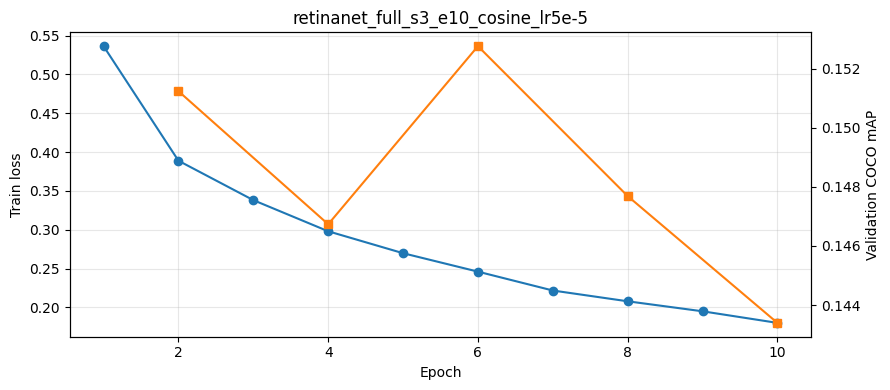

Artifacts in: /kaggle/working/retinanet_full_s3_e10_cosine_lr5e-5
  best_model.pt — best selected official-val model
  last.pt — checkpoint for resume
  train_history.csv / training_curves.png
  val_inference_comparison.json / selected_inference.json
  /kaggle/working/submission.csv — Kaggle upload


In [15]:
import matplotlib.pyplot as plt
if history:
    df=pd.DataFrame(history)
    fig,ax=plt.subplots(figsize=(9,4))
    ax.plot(df['epoch'],df['loss'],marker='o',label='Train loss')
    ax.set_xlabel('Epoch');ax.set_ylabel('Train loss');ax.grid(alpha=0.3)
    if 'val_mAP' in df:
        ax2=ax.twinx()
        sub=df.dropna(subset=['val_mAP'])
        ax2.plot(sub['epoch'],sub['val_mAP'],marker='s',label='Official val mAP',color='tab:orange')
        ax2.set_ylabel('Validation COCO mAP')
    plt.title(RUN_NAME);fig.tight_layout()
    fig.savefig(OUT/'training_curves.png',dpi=160)
    plt.show()
print('Artifacts in:',OUT)
print('  best_model.pt — best selected official-val model')
print('  last.pt — checkpoint for resume')
print('  train_history.csv / training_curves.png')
print('  val_inference_comparison.json / selected_inference.json')
print('  /kaggle/working/submission.csv — Kaggle upload')